# Test Linear Model (least squares) Fixed Point Equations (with a change point)

  0%|          | 0/8 [00:00<?, ?it/s]

δ =  1.8


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1762 [00:00<?, ?it/s]

Optimization Results: x =  [1.15999102 1.38851227 1.66163277] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 12, 'njev': 1, 'fjac': array([[-0.90690426,  0.41291572,  0.08381689],
       [ 0.38886152,  0.89685951, -0.21078363],
       [ 0.16220786,  0.15856741,  0.97393274]]), 'r': array([ 0.69406283, -0.55783684, -0.13562382, -0.64327391,  0.30625564,
       -0.1977586 ]), 'qtf': array([-7.86817479e-12,  8.63777568e-11, -1.07607835e-10]), 'fvec': array([ 3.33510997e-13,  8.46878123e-13, -1.86739513e-12])}
μ̃_arr:  [0.6383475 0.3616525]
σ̃ =  1.387990305179809
Regressing on signal  0
Optimization Results: x =  [1.42417396 1.20286185 1.65820445] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 12, 'njev': 1, 'fjac': array([[-0.94169039,  0.32416419,  0.09020409],
       [-0.30333905, -0.93388155,  0.18934272],
       [-0.14561807, -0.1509398 , -0.97775895]]), 'r': array([ 0.8368377 , -0.47293666, -0.14353971,  0.51188875, -0.32159434,
        0.20

 12%|█▎        | 1/8 [00:06<00:46,  6.68s/it]

... (31 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/4898 [00:00<?, ?it/s]

Optimization Results: x =  [0.60498241 1.14952795 0.27025967] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 12, 'njev': 1, 'fjac': array([[-0.97792308,  0.20714992, -0.02748389],
       [-0.20882693, -0.9735702 ,  0.09247904],
       [ 0.00760047, -0.09617676, -0.99533525]]), 'r': array([ 0.76354306, -0.20907909,  0.03844424,  1.09077377, -1.22226555,
        2.4867717 ]), 'qtf': array([-1.59034093e-11,  2.34661281e-10, -2.38779911e-10]), 'fvec': array([ 1.69175784e-12,  4.93538543e-12, -5.87085935e-12])}
μ̃_arr:  [0.71884777 0.28115223]
σ̃ =  0.9835121330146046
Regressing on signal  0
Optimization Results: x =  [1.14906275 0.60446013 0.27013292] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 12, 'njev': 1, 'fjac': array([[ 0.99430638,  0.05651437, -0.09033792],
       [ 0.05181107, -0.99721808, -0.05358844],
       [ 0.09311512, -0.04860283,  0.99446837]]), 'r': array([-1.13089316,  0.1505871 ,  1.21693179,  0.74322353, -0.1118497 ,
       -2

100%|██████████| 8/8 [00:55<00:00,  6.91s/it]


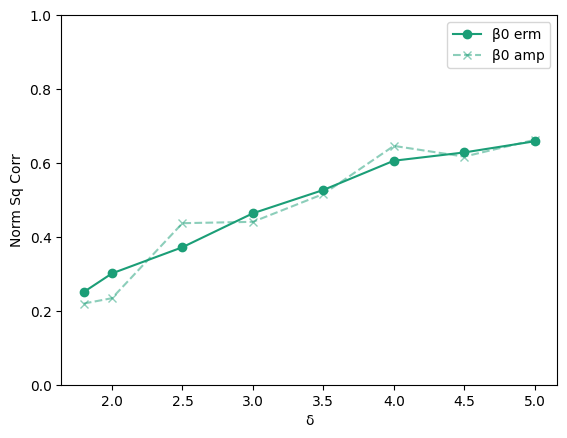

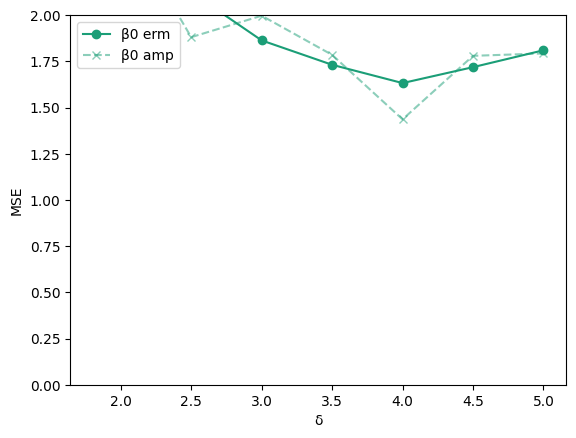

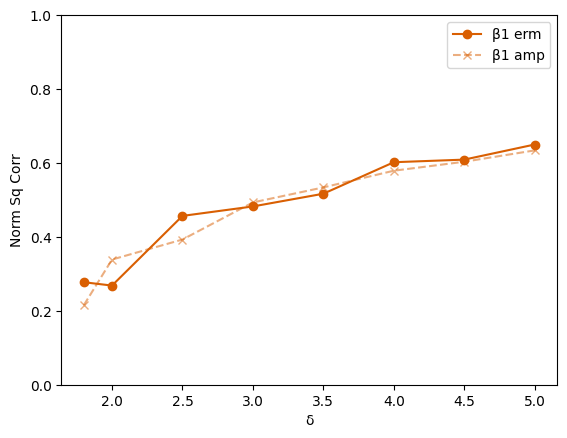

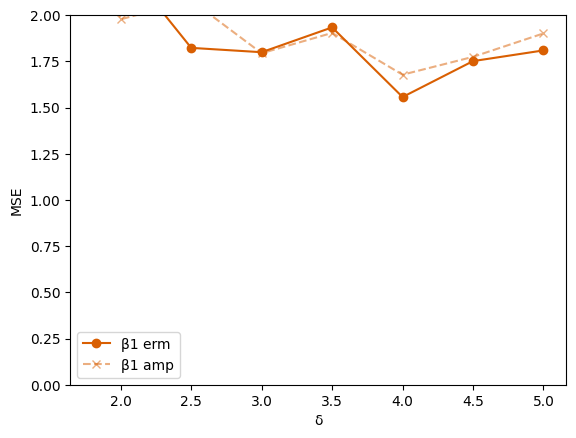

In [1]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 1000
L = 2 # num signals. L-1 changepoints

δ_list = [1.8, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
noise_std = 0.5
M = lambda t: jnp.power(t, 2)

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))

    Θ = X @ B̃
    y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

    # --- Run Weighted ERM and compare with the fixed point equations --- #
    B̂ = np.zeros((p, L))

    for ℓ_ in range(L):
        # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
        # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
        π = ϕ[ℓ_, :]
        ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
        μ̃_arr, σ̃, μ_arr, σ = fp_lin_model(π, M, ρ, L, fractional_chgpt_locations, δ, n, ε)
        print("σ̃ = ", σ̃)
        β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

        print("Regressing on signal ", ℓ_)
        sample_weight = π
        sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
        sk_lin_reg.fit(X, y, sample_weight = sample_weight)
        β̂ = sk_lin_reg.coef_

        B̂[:, ℓ_] = β̂
        erm_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
        amp_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

        comparison_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp.flatten(), β̂.flatten()))
        comparison_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), β̂.flatten()))
        erm_MSE_list[ℓ_].append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
        amp_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), B̃[:, ℓ_]))
        G = np.random.randn(p)
        theory_MSE_list[ℓ_].append(WERM.MSE(σ̃ * G, np.zeros(p)))

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
for ℓ_ in range(L):
    # Sqcorr plots
    plt.errorbar(δ_list, erm_corr_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
    plt.ylim((0, 1))
    plt.xlabel("δ")
    plt.ylabel("Norm Sq Corr")
    plt.legend()
    plt.show()

    # MSE plots
    # plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
    # plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
    plt.ylim((0, 2))
    plt.xlabel("δ")
    plt.ylabel("MSE")
    plt.legend()
    plt.show()

# Test Linear Model with Huber Loss 

  0%|          | 0/8 [00:00<?, ?it/s]

δ =  1.8


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1762 [00:00<?, ?it/s]

Optimization Results: x =  [0.8036077  0.88175887 1.6620638 ] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 12, 'njev': 1, 'fjac': array([[-0.83608006,  0.54854397, -0.00834559],
       [ 0.54857841,  0.83609559, -0.0024288 ],
       [-0.00564541,  0.00660889,  0.99996223]]), 'r': array([ 0.69485936, -0.62062983, -0.05533413, -0.5528703 ,  0.2256394 ,
       -0.22453579]), 'qtf': array([ 8.48074674e-12, -3.32031924e-11,  1.68306457e-12]), 'fvec': array([-2.62678768e-13, -2.39697151e-13,  1.77635684e-14])}
μ̃_arr:  [0.63738079 0.36261921]
σ̃ =  1.0241836969284046
Regressing on signal  0


 12%|█▎        | 1/8 [00:06<00:48,  7.00s/it]

... (31 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/4898 [00:00<?, ?it/s]

Optimization Results: x =  [0.38951106 0.60648137 0.27315063] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 14, 'njev': 1, 'fjac': array([[-0.9288745 ,  0.36282784, -0.07448577],
       [-0.36549812, -0.93046072,  0.02557301],
       [ 0.06002748, -0.05097853, -0.99689412]]), 'r': array([ 0.72127505, -0.28008912, -0.21093375,  1.14241046, -1.32512254,
        2.4956494 ]), 'qtf': array([1.26560872e-09, 1.62997073e-09, 5.31710338e-10]), 'fvec': array([-8.90232332e-13, -4.76396700e-13, -4.38538095e-13])}
μ̃_arr:  [0.7198344 0.2801656]
σ̃ =  0.7521270822160097
Regressing on signal  0


100%|██████████| 8/8 [00:45<00:00,  5.63s/it]


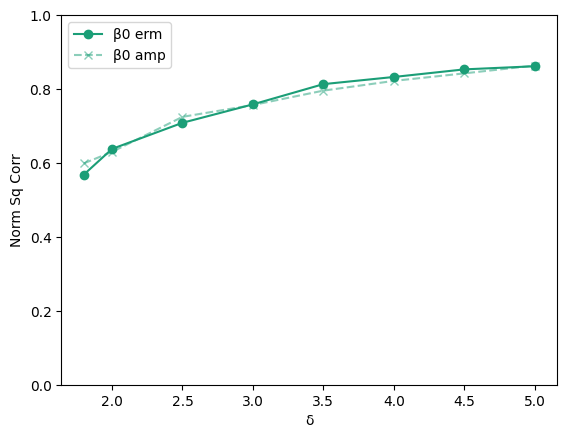

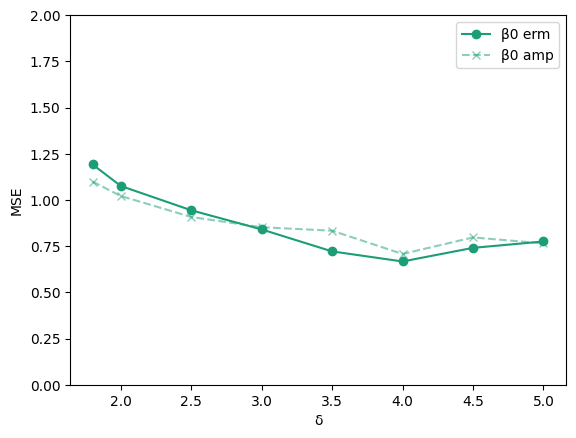

In [1]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 1000
L = 2 # num signals. L-1 changepoints

δ_list = [1.8, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
noise_std = 0.5
M = lambda t: jnp.power(t, 2)

def huber_loss(t, epsilon = 1.35):
    residual = t
    condition = jnp.abs(residual) < epsilon
    squared_loss = jnp.square(residual)
    linear_loss = 2 * epsilon * (jnp.abs(residual) - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 1.0
    # B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    B̃_cov = κ**2 * δ * np.array([[1.0, 0.75], [0.75, 1.0]]) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))

    Θ = X @ B̃
    y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

    # --- Run Weighted ERM and compare with the fixed point equations --- #
    B̂ = np.zeros((p, L))

    ℓ_ = 0
    # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
    μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(huber_loss, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
    print("σ̃ = ", σ̃)
    β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

    print("Regressing on signal ", ℓ_)
    sample_weight = (n - np.arange(n)) / n

    # Find minimum of Huber loss
    huber_loss_wrapper = lambda β: jnp.multiply(huber_loss(y - X @ β), sample_weight).sum()
    res = scipy.optimize.minimize(huber_loss_wrapper, np.random.randn(p), jac = jax.grad(huber_loss_wrapper))
    β̂ = res.x

    B̂[:, ℓ_] = β̂
    erm_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
    amp_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

    comparison_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp.flatten(), β̂.flatten()))
    comparison_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), β̂.flatten()))
    erm_MSE_list[ℓ_].append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
    amp_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), B̃[:, ℓ_]))
    G = np.random.randn(p)
    theory_MSE_list[ℓ_].append(WERM.MSE(σ̃ * G, np.zeros(p)))

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
ℓ_ = 0
plt.errorbar(δ_list, erm_corr_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
# plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
# plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Linear Model with change points: estimate ρ

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 2000
L = 2 # num signals. L-1 changepoints

δ_list = [2.0]
noise_std = 0.2
M = lambda t: jnp.power(t, 2)

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 2.3
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    ρ̂ = ρ
    print("True ρ: ", ρ)

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))
    Θ = X @ B̃
    y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

    Δρ_arr = []
    # Ideas to fix: use the exact same noise vector, 
    for j in tqdm(range(10)): 
        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        Θ̂_erm = np.zeros((n, L))
        Θ_t_erm = np.zeros((n, L))
        ν = np.zeros((L, L))
        κ_mat = np.zeros((L, L))

        for ℓ_ in range(L):

            # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
            # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
            # π = ϕ[ℓ_, :]
            π = np.ones(n) # Set to a trivial prior to test
            ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
            μ̃_arr, σ̃, μ_arr, σ, b = fp_lin_model(π, M, ρ̂, L, fractional_chgpt_locations, δ, n, ε)
            ν[:, ℓ_] = μ̃_arr
            κ_mat[ℓ_, ℓ_] = (σ̃)**2 / δ
            # print("σ̃ = ", σ̃)
            β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

            # print("Regressing on signal ", ℓ_)
            sample_weight = π
            sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
            sk_lin_reg.fit(X, y, sample_weight = sample_weight)
            β̂ = sk_lin_reg.coef_

            B̂[:, ℓ_] = β̂
            Θ̂_erm[:, ℓ_] = X @ β̂
            print("### --- Debiasing... --- ###")
            Θ_t_erm[:, ℓ_] = debias_M_est(X @ β̂, y, b, π, X @ β̂)
            # loss = lambda u, v: M(u - v)
            # β̂_amp_algo, θ̂_amp_algo, β_t, θ_t = WERM.amp(X, y, n, p, π, loss, max_iter = 20)
            # Θ_t_erm[:, ℓ_] = θ_t
            
            # erm_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
            # amp_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

            # comparison_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp.flatten(), β̂.flatten()))
            # comparison_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), β̂.flatten()))
            # erm_MSE_list[ℓ_].append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
            # amp_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), B̃[:, ℓ_]))
            # G = np.random.randn(p)
            # theory_MSE_list[ℓ_].append(WERM.MSE(σ̃ * G, np.zeros(p)))

        # Solve for ρ
        # Check whether \nu^T \rho \nu + \kappa is positive definite and whether ν is invertible
        rhs = ν.T @ ρ @ ν + κ_mat
        assert np.all(np.linalg.eigvals(rhs) > 0)

        # ρ̂ = np.linalg.inv(ν).T @ ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) @ np.linalg.inv(ν) # Attempt to solve for ρ using a solver instead?
        ρ̂ = ρ
        lhs = (1/n * Θ_t_erm.T @ Θ_t_erm)
        print("lhs: ", lhs)
        print("rhs: ", rhs)
        print("lhs - rhs: ", lhs - rhs)
        print("ν: ", ν)
        print("κ_mat: ", κ_mat)

        print("ρ: ", ρ)
        print("ρ̂: ", ρ̂)
        print("Δρ: ", np.linalg.norm(ρ - ρ̂))
        print("ρ - ρ̂: ", ρ - ρ̂)
        Δρ_arr.append(np.linalg.norm(ρ - ρ̂))

    plt.plot(Δρ_arr)
    plt.title("Δρ")
    plt.show()

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
for ℓ_ in range(L):
    # Sqcorr plots
    plt.errorbar(δ_list, erm_corr_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
    plt.ylim((0, 1))
    plt.xlabel("δ")
    plt.ylabel("Norm Sq Corr")
    plt.legend()
    plt.show()

    # MSE plots
    # plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
    # plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
    plt.ylim((0, 2))
    plt.xlabel("δ")
    plt.ylabel("MSE")
    plt.legend()
    plt.show()

  0%|          | 0/1 [00:00<?, ?it/s]

δ =  2.0


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/4898 [00:00<?, ?it/s]

True ρ:  [[5.30503167 0.06057046]
 [0.06057046 5.04832244]]


  0%|          | 0/10 [00:00<?, ?it/s]

# Linear Model without change points: estimate γ

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 2000
L = 1 # num signals. L-1 changepoints

δ_list = [3.0 for _ in range(30)]
noise_std = 0.2
# M = lambda t: jnp.power(t, 2)

def huber_loss(t, epsilon = 1.35):
    residual = t
    condition = jnp.abs(residual) < epsilon
    squared_loss = jnp.square(residual)
    linear_loss = 2 * epsilon * (jnp.abs(residual) - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)
def M(t): return huber_loss(t)

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

Δρ_trials_list = [[] for _ in δ_list]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)

    # Gaussian Signal Prior
    γ_squared = 2.3
    B̃_cov = γ_squared * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    ρ̂ = np.eye(L)
    print("True ρ: ", ρ)

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))
    Θ = X @ B̃
    ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
    y = Θ.flatten() + ε.flatten()

    Δρ_arr = [np.linalg.norm(ρ - ρ̂)]
    print("Δρ: ", np.linalg.norm(ρ - ρ̂))
    # Ideas to fix: use the exact same noise vector, 
    for j in tqdm(range(4)): 
        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        Θ̂_erm = np.zeros((n, L))
        Θ_t_erm = np.zeros((n, L))
        ν = np.zeros((L, L))
        κ_mat = np.zeros((L, L))

        # π = ϕ[ℓ_, :]
        π = np.ones(n) # Set to a trivial prior to test
        ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
        fractional_chgpt_locations = np.array([])
        μ̃_arr, σ̃, μ_arr, σ, b = fp_lin_model(π, M, ρ̂, L, fractional_chgpt_locations, δ, n, ε)
        ν = μ̃_arr
        κ_mat = (σ̃)**2 / δ
        # print("σ̃ = ", σ̃)
        β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

        # print("Regressing on signal ", ℓ_)
        # sample_weight = π
        # sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
        # sk_lin_reg.fit(X, y, sample_weight = sample_weight)
        # β̂ = sk_lin_reg.coef_

        # B̂[:, 0] = β̂
        # Θ̂_erm[:, 0] = X @ β̂
        print("### --- Debiasing... --- ###")
        # Run actual AMP
        loss = lambda u, v: M(u - v)
        β̂_amp_algo, θ̂_amp_algo, β_t, θ_t = WERM.amp(X, y, n, p, π, loss, max_iter = 20)
        Θ_t_erm[:, 0] = θ_t
        # Θ_t_erm[:, 0] = debias_M_est(X @ β̂, y, b, π, X @ β̂)

        # Solve for ρ
        # Check whether \nu^T \rho \nu + \kappa is positive definite and whether ν is invertible
        rhs = ν[0]**2 * ρ[0] + κ_mat
        # ρ̂ = np.linalg.inv(ν).T @ ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) @ np.linalg.inv(ν) # Attempt to solve for ρ using a solver instead?
        ρ̂ = ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) * (ν[0])**(-2) # Attempt to solve for ρ using a solver instead?
        # ρ̂ = ρ
        lhs = (1/n * Θ_t_erm.T @ Θ_t_erm)
        print("lhs: ", lhs)
        print("rhs: ", rhs)
        print("lhs - rhs: ", lhs - rhs)
        print("ν: ", ν)
        print("κ_mat: ", κ_mat)

        print("ρ: ", ρ)
        print("ρ̂: ", ρ̂)
        print("Δρ: ", np.linalg.norm(ρ - ρ̂))
        print("ρ - ρ̂: ", ρ - ρ̂)
        Δρ_arr.append(np.linalg.norm(ρ - ρ̂))

    plt.plot(Δρ_arr)
    plt.title("Δρ")
    plt.show()

    Δρ_trials_list[i] = (ρ - ρ̂)[0][0]

  0%|          | 0/30 [00:00<?, ?it/s]

δ =  3.0
True ρ:  [[2.29926312]]
Δρ:  1.2992631192620925


  0%|          | 0/4 [00:00<?, ?it/s]

Optimization Results: x =  [0.13915975 0.25      ] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 17, 'njev': 2, 'fjac': array([[-0.99974797, -0.02245001],
       [ 0.02245001, -0.99974797]]), 'r': array([ 0.67834903, -0.34038738,  2.71251879]), 'qtf': array([ 1.50002317e-10, -1.97273537e-10]), 'fvec': array([ 6.63358257e-14, -8.23785484e-14])}
μ̃_arr:  [1.]
### --- Debiasing... --- ###


  0%|          | 0/20 [00:00<?, ?it/s]

c:  -0.8965
Normalized MSE:  inf
c:  -1.1273399083057893
Normalized MSE:  0.0016907894014213808
c:  -1.2565751252482205
Normalized MSE:  6.540006530397817e-05
c:  -1.306726102282859
Normalized MSE:  2.9219610616825734e-05
c:  -1.3243446746573966
Normalized MSE:  1.106512042235334e-05
c:  -1.3303235869833683
Normalized MSE:  3.967475627603228e-06
c:  -1.3323285725124046
Normalized MSE:  1.427153942515998e-06
c:  -1.3329982447177355
Normalized MSE:  5.042366267769913e-07
c:  -1.333221618410936
Normalized MSE:  1.7466464331795598e-07
c:  -1.3332960929457154
Normalized MSE:  5.8297022484319916e-08
c:  -1.3333209196396467
Normalized MSE:  1.945813197342021e-08
c:  -1.3333291954097533
Normalized MSE:  6.260100145377167e-09
c:  -1.3333319540226187
Normalized MSE:  1.961548376423914e-09
c:  -1.333332873562779
Normalized MSE:  6.610417705828455e-10
c:  -1.3333331800764463
Normalized MSE:  2.0970115871136702e-10
c:  -1.3333332822477004
Normalized MSE:  6.669199798211594e-11
c:  -1.33333331630478

 25%|██▌       | 1/4 [01:18<03:55, 78.51s/it]

c:  -1.3333333327026462
Normalized MSE:  6.334287879950161e-13
lhs:  [[2.31524884]]
rhs:  [2.31862856]
lhs - rhs:  [[-0.00337972]]
ν:  [1.]
κ_mat:  0.01936543673002991
ρ:  [[2.29926312]]
ρ̂:  [[2.2958834]]
Δρ:  0.003379716920655529
ρ - ρ̂:  [[0.00337972]]
Optimization Results: x =  [0.1420479 0.25     ] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 18, 'njev': 1, 'fjac': array([[-0.99960252, -0.02819208],
       [ 0.02819208, -0.99960252]]), 'r': array([ 0.5936437 , -1.69293612,  3.01618855]), 'qtf': array([ 2.91613955e-09, -7.10659368e-10]), 'fvec': array([ 6.55919763e-13, -1.41220369e-13])}
μ̃_arr:  [1.]
### --- Debiasing... --- ###


  0%|          | 0/20 [00:00<?, ?it/s]

c:  -0.8993333333333333
Normalized MSE:  inf
c:  -1.1317281112530153
Normalized MSE:  0.001837767667786363
c:  -1.258178551717071
Normalized MSE:  6.489499300489029e-05
c:  -1.3073036103895601
Normalized MSE:  2.8373919240339e-05
c:  -1.3245423455302847
Normalized MSE:  1.054990065994643e-05
c:  -1.3303900669562407
Normalized MSE:  3.7810280989929356e-06
c:  -1.3323507986102618
Normalized MSE:  1.4109993676862359e-06
c:  -1.3330056607841476
Normalized MSE:  4.845417617096595e-07
c:  -1.333224091252456
Normalized MSE:  1.6100080078397194e-07


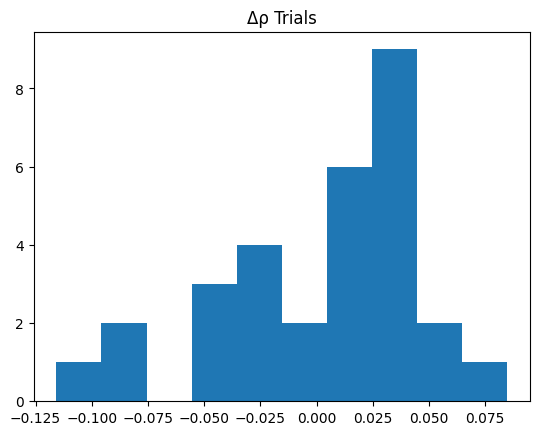

Mean:  0.0012376678106404526
Std:  0.04540794343623711


In [3]:
# Δρ_trials_list = np.array(Δρ_trials_list)
# Plot a histogram of Δρ_trials_list
plt.hist(Δρ_trials_list)
plt.title("Δρ Trials")
plt.show()

print("Mean: ", np.mean(Δρ_trials_list))
print("Std: ", np.std(Δρ_trials_list))